# Skip (Residual) Connections: Showing Their Advantage

A teaching notebook. Every experiment is a **controlled A/B**: the same network with and without the `+ x`, with identical widths, seeds, optimizer and steps, so the skip connection is the only difference.

| # | Experiment | Question it answers |
|---|---|---|
| 0 | Building blocks | What is a residual block? (your original code) |
| 1 | Gradient flow and signal propagation | **Why** do skips help? |
| 2 | Depth sweep | **So what?** Do deeper plain nets get worse *training* loss? |
| 3 | Identity at initialization | What does "learning the residual" mean? |
| 4 | Loss landscape | What can a 2D slice of the loss surface tell us (and not tell us)? |
| 5 | Quantitative sharpness | Does a slice-independent number agree with the pictures? (a reality check) |

Everything runs on CPU in a few minutes.

In [1]:
import time, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_moons

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(2)
print("torch", torch.__version__)

torch 2.15.0+cu132


## 0. The building blocks (original code)

A residual block computes `y = ReLU(F(x) + x)`, where `F` is two linear layers with a ReLU between them. When input and output sizes differ, the shortcut needs a projection so the shapes match for the addition.

In [2]:
class DenseResidualBlock(nn.Module):
    def __init__(self, features: int):
        super().__init__()
        # Transformation path: F(x)
        self.fc1 = nn.Linear(features, features)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(features, features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x                      # 1. store original input
        out = self.fc1(x)                 # 2. transformation path
        out = self.relu(out)
        out = self.fc2(out)
        out = out + identity              # 3. add the shortcut
        return self.relu(out)             # 4. final non-linearity


class ProjectedDenseResidualBlock(nn.Module):
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.fc1 = nn.Linear(in_features, out_features)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(out_features, out_features)
        # Shortcut: project to match dimensions if needed
        if in_features != out_features:
            self.shortcut = nn.Linear(in_features, out_features, bias=False)
        else:
            self.shortcut = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = self.shortcut(x)
        out = self.fc2(self.relu(self.fc1(x)))
        return self.relu(out + identity)


x = torch.randn(4, 8)
print("DenseResidualBlock:         ", DenseResidualBlock(8)(x).shape)
print("ProjectedDenseResidualBlock:", ProjectedDenseResidualBlock(8, 16)(x).shape)

DenseResidualBlock:          torch.Size([4, 8])
ProjectedDenseResidualBlock: torch.Size([4, 16])


### A switchable block for the experiments

To make a fair comparison we need **one** block class where the skip can be switched off, so plain and residual nets have exactly the same parameters and initialization. Two optional extras are used later:

- `preact=True`: pre-activation variant `x + F(relu(norm(x)))`. The identity path has no ReLU on it (as in Transformers).
- `norm=True`: adds a LayerNorm in the branch, to show skips and normalization are complementary.

In [3]:
class Block(nn.Module):
    def __init__(self, d, skip=True, preact=False, norm=False):
        super().__init__()
        self.fc1, self.fc2 = nn.Linear(d, d), nn.Linear(d, d)
        self.skip, self.preact = skip, preact
        self.norm = nn.LayerNorm(d) if norm else nn.Identity()

    def forward(self, x):
        if self.preact:
            branch = self.fc2(torch.relu(self.fc1(torch.relu(self.norm(x)))))
            return x + branch if self.skip else branch
        branch = self.norm(self.fc2(torch.relu(self.fc1(x))))
        if self.skip:
            branch = branch + x          # <- the only difference
        return torch.relu(branch)


def make_net(n_blocks, skip, d=32, in_dim=2, out_dim=1, **kw):
    return nn.Sequential(
        nn.Linear(in_dim, d),
        *[Block(d, skip, **kw) for _ in range(n_blocks)],
        nn.Linear(d, out_dim),
    )

# sanity check: same seed => plain and residual nets start from identical weights
torch.manual_seed(0); a = make_net(5, False)
torch.manual_seed(0); b = make_net(5, True)
print("identical init:", all(torch.equal(p, q) for p, q in zip(a.parameters(), b.parameters())))

identical init: True


## Experiment 1: gradient flow and signal propagation (the "why")

For `y = F(x) + x`, the chain rule gives

$$\frac{\partial L}{\partial x} = \frac{\partial L}{\partial y}\left(\frac{\partial F}{\partial x} + 1\right).$$

That `+ 1` is a direct path for gradients. No training is needed to see its effect: build a deep net, do one backward pass at initialization, and look at the gradient norm of every block.

**What to look for:** in the plain net, gradient norm falls by orders of magnitude toward the input (block 0). In the residual net it stays roughly flat.

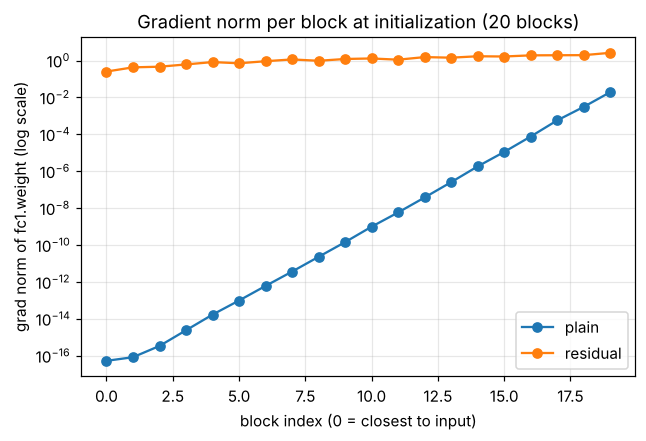

plain     grad norm at block 0 = 5.38e-17, at last block = 1.95e-02
residual  grad norm at block 0 = 2.55e-01, at last block = 2.63e+00
(float32 underflows to exactly 0 for much deeper plain nets, which is itself the point)


In [4]:
def grad_norms(skip, n_blocks=20, d=32, seeds=5, **kw):
    """Gradient norm of fc1.weight in every block after one backward pass at init."""
    out = []
    for s in range(seeds):
        torch.manual_seed(s)
        net = make_net(n_blocks, skip, d, in_dim=d, **kw)
        net[0] = nn.Identity()                       # feed d-dim input straight in
        xb, yb = torch.randn(256, d), torch.randn(256, 1)
        F.mse_loss(net(xb), yb).backward()
        out.append([blk.fc1.weight.grad.norm().item() for blk in net[1:-1]])
    return np.array(out).mean(0)

g_plain, g_res = grad_norms(False), grad_norms(True)

plt.figure(figsize=(6.5, 4))
plt.semilogy(g_plain, "o-", label="plain")
plt.semilogy(g_res, "o-", label="residual")
plt.xlabel("block index (0 = closest to input)")
plt.ylabel("grad norm of fc1.weight (log scale)")
plt.title("Gradient norm per block at initialization (20 blocks)")
plt.legend(); plt.show()

for name, g in (("plain", g_plain), ("residual", g_res)):
    print(f"{name:9s} grad norm at block 0 = {g[0]:.2e}, at last block = {g[-1]:.2e}")
print("(float32 underflows to exactly 0 for much deeper plain nets, which is itself the point)")

### 1b. Forward signal propagation

Skips help the forward pass too. Track the activation scale through the depth of the network at initialization.

**What to look for:** with PyTorch's default initialization, activations in the plain net shrink layer after layer, so the output barely depends on the input. In the residual net the signal is preserved (and, without normalization, tends to grow slowly, which is the reason normalization layers and scaled branches are used in practice).

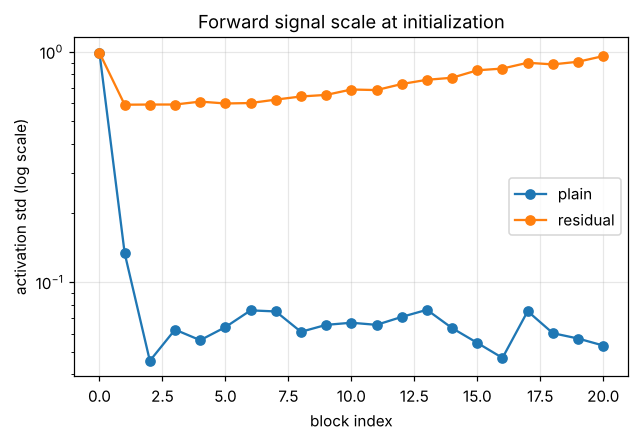

In [5]:
@torch.no_grad()
def activation_scale(skip, n_blocks=20, d=32, **kw):
    torch.manual_seed(0)
    net = make_net(n_blocks, skip, d, in_dim=d, **kw)
    net[0] = nn.Identity()
    h = torch.randn(512, d)
    stds = [h.std().item()]
    for blk in net[1:-1]:
        h = blk(h); stds.append(h.std().item())
    return stds

plt.figure(figsize=(6.5, 4))
plt.semilogy(activation_scale(False), "o-", label="plain")
plt.semilogy(activation_scale(True), "o-", label="residual")
plt.xlabel("block index"); plt.ylabel("activation std (log scale)")
plt.title("Forward signal scale at initialization"); plt.legend(); plt.show()

## Experiment 2: depth sweep (the "so what")

This reproduces the **degradation problem** from the ResNet paper: adding layers to a plain network makes *training* loss worse. Because we measure training loss, this cannot be blamed on overfitting. It is an optimization failure.

We use three arms: plain, residual (post-activation, your block), and residual (pre-activation). Each point is the mean of 3 seeds with min/max shown as a band.

In [6]:
X_np, y_np = make_moons(1000, noise=0.15, random_state=0)
X = torch.tensor(X_np, dtype=torch.float32)
y = torch.tensor(y_np, dtype=torch.float32).unsqueeze(1)
CHANCE = math.log(2)       # BCE of a constant 0.5 prediction
print("chance-level BCE =", round(CHANCE, 4))

def train(n_blocks, skip, steps=400, lr=1e-3, seed=0, **kw):
    torch.manual_seed(seed)
    net = make_net(n_blocks, skip, **kw)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    hist = []
    for _ in range(steps):
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(net(X), y)
        loss.backward(); opt.step()
        hist.append(loss.item())
    return net, hist

chance-level BCE = 0.6931


plain                  [0.034 0.021 0.248 0.693 0.693]


residual (post-act)    [0.046 0.018 0.017 0.014 0.013]


residual (pre-act)     [0.029 0.017 0.014 0.018 0.011]
(133s)


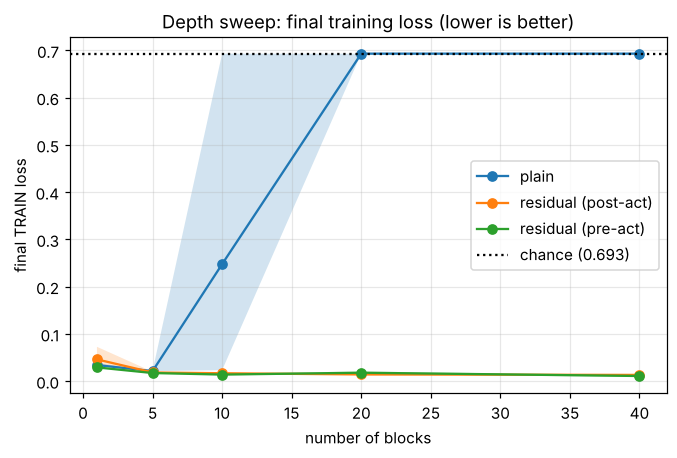

In [7]:
depths = [1, 5, 10, 20, 40]
arms = {
    "plain":              dict(skip=False),
    "residual (post-act)": dict(skip=True),
    "residual (pre-act)":  dict(skip=True, preact=True),
}
seeds = [0, 1, 2]
results = {name: np.zeros((len(depths), len(seeds))) for name in arms}

t0 = time.time()
for name, cfg in arms.items():
    for i, dpt in enumerate(depths):
        for j, s in enumerate(seeds):
            _, h = train(dpt, seed=s, **cfg)
            results[name][i, j] = h[-1]
    print(f"{name:22s}", np.round(results[name].mean(1), 3))
print(f"({time.time()-t0:.0f}s)")

plt.figure(figsize=(7, 4.2))
for name, r in results.items():
    plt.plot(depths, r.mean(1), "o-", label=name)
    plt.fill_between(depths, r.min(1), r.max(1), alpha=0.2)
plt.axhline(CHANCE, color="k", ls=":", label="chance (0.693)")
plt.xlabel("number of blocks"); plt.ylabel("final TRAIN loss")
plt.title("Depth sweep: final training loss (lower is better)")
plt.legend(); plt.show()

### 2b. Training curves at the deepest setting

The most visual moment: same depth, same everything, only the skip differs.

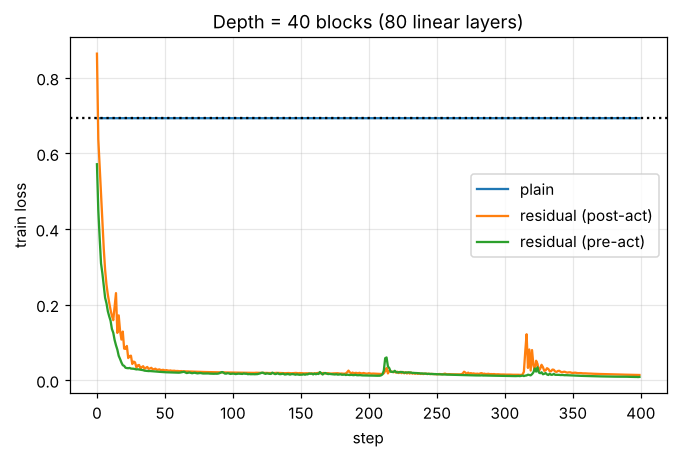

In [8]:
plt.figure(figsize=(7, 4.2))
for name, cfg in arms.items():
    _, h = train(40, seed=0, **cfg)
    plt.plot(h, label=name)
plt.axhline(CHANCE, color="k", ls=":")
plt.xlabel("step"); plt.ylabel("train loss"); plt.title("Depth = 40 blocks (80 linear layers)")
plt.legend(); plt.show()

### 2c. Skips and normalization are complementary

A fair question from students: "doesn't normalization already fix this?" Add LayerNorm to both arms and repeat the sweep.

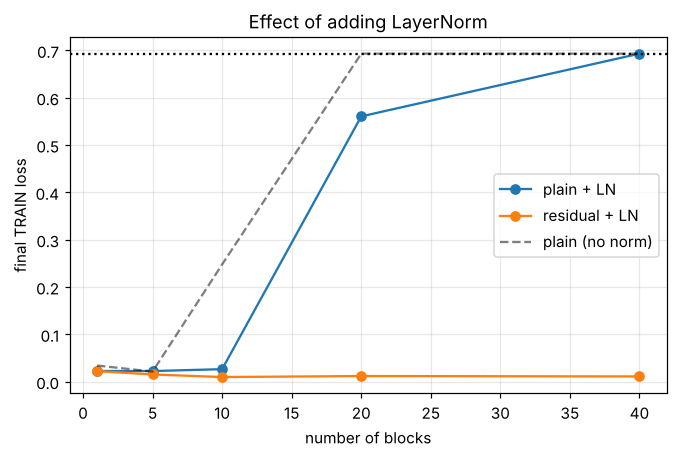

{'plain + LN': array([0.023, 0.022, 0.026, 0.561, 0.693]), 'residual + LN': array([0.022, 0.015, 0.01 , 0.012, 0.011])}


In [9]:
norm_res = {"plain + LN": np.zeros(len(depths)), "residual + LN": np.zeros(len(depths))}
for i, dpt in enumerate(depths):
    for name, sk in (("plain + LN", False), ("residual + LN", True)):
        norm_res[name][i] = np.mean([train(dpt, sk, seed=s, norm=True)[1][-1] for s in seeds])

plt.figure(figsize=(7, 4.2))
for name, r in norm_res.items():
    plt.plot(depths, r, "o-", label=name)
plt.plot(depths, results["plain"].mean(1), "k--", alpha=0.5, label="plain (no norm)")
plt.axhline(CHANCE, color="k", ls=":")
plt.xlabel("number of blocks"); plt.ylabel("final TRAIN loss")
plt.title("Effect of adding LayerNorm"); plt.legend(); plt.show()
print({k: np.round(v, 3) for k, v in norm_res.items()})

## Experiment 3: identity at initialization (the "residual" intuition)

A residual block only has to learn `F(x) = H(x) - x`. If the best thing a block can do is "nothing", it just needs `F` close to 0. Zero-initializing the last layer of the branch makes the block *exactly* the identity.

residual block with zero-init branch is identity: True
plain block with zero-init output layer returns:   0.0 (all zeros)


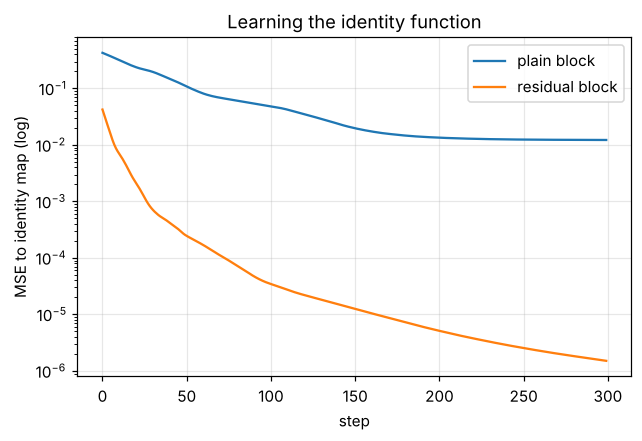

In [10]:
b = Block(8, skip=True)
nn.init.zeros_(b.fc2.weight); nn.init.zeros_(b.fc2.bias)
xin = torch.relu(torch.randn(4, 8))   # post-ReLU input, like a mid-network activation
print("residual block with zero-init branch is identity:", torch.allclose(b(xin), xin))

# Contrast: a plain block with the same zero-init output layer collapses everything to 0.
p = Block(8, skip=False)
nn.init.zeros_(p.fc2.weight); nn.init.zeros_(p.fc2.bias)
print("plain block with zero-init output layer returns:  ", p(xin).abs().max().item(), "(all zeros)")

# A plain block must LEARN to be the identity. How hard is it?
def fit_identity(skip, steps=300):
    torch.manual_seed(0)
    blk = Block(8, skip)
    opt = torch.optim.Adam(blk.parameters(), lr=1e-2)
    xs = torch.relu(torch.randn(512, 8))
    hist = []
    for _ in range(steps):
        opt.zero_grad(); l = F.mse_loss(blk(xs), xs); l.backward(); opt.step(); hist.append(l.item())
    return hist

plt.figure(figsize=(6.5, 4))
plt.semilogy(fit_identity(False), label="plain block")
plt.semilogy(fit_identity(True), label="residual block")
plt.xlabel("step"); plt.ylabel("MSE to identity map (log)")
plt.title("Learning the identity function"); plt.legend(); plt.show()

## Experiment 4: the loss landscape (what a 2D slice can and cannot tell us)

Following Li et al. (2018), *Visualizing the Loss Landscape of Neural Nets*. The loss lives in a space with thousands of dimensions, so we look at a 2D slice around the trained weights `theta*`:

$$L(\alpha, \beta) = \mathrm{loss}(\theta^* + \alpha\, d_1 + \beta\, d_2)$$

where `d1`, `d2` are random directions. The key detail is **filter normalization**: each row of a random direction is rescaled to match the norm of the corresponding row of `theta*`. Without it, plain and residual nets have different weight scales and the plots are not comparable.

**Read this before running the cells.** The famous "smooth vs chaotic" pictures in Li et al. come from deep BatchNorm CNNs on CIFAR-10 (ResNet-56 and ResNet-110 style). On this tiny MLP the picture is less clean, and the notebook reports what actually happens rather than what the paper's figures suggest. That is a useful lesson in itself:

- A slice is evidence, not proof.
- A net that failed to train (loss stuck at 0.693) has a perfectly flat plateau around it. That is *not* a smooth landscape, it is a dead network.
- Without normalization, perturbing the weights of a deep residual net blows up activations (each block adds to the stream), so the residual basin can look narrow and steep even though it trains well.

In [11]:
def random_direction(net, gen):
    """Filter-normalized random direction (weight matrices only; biases/norm params get 0)."""
    d = []
    for p in net.parameters():
        if p.dim() > 1:
            r = torch.randn(p.shape, generator=gen)
            r = r / (r.norm(dim=1, keepdim=True) + 1e-10) * p.norm(dim=1, keepdim=True)
            d.append(r)
        else:
            d.append(torch.zeros_like(p))
    return d

@torch.no_grad()
def loss_at(net, base, dirs, coeffs):
    for p, p0, *ds in zip(net.parameters(), base, *dirs):
        p.copy_(p0 + sum(c * d for c, d in zip(coeffs, ds)))
    return F.binary_cross_entropy_with_logits(net(X), y).item()

@torch.no_grad()
def loss_surface(net, span=1.0, n=31, seed=1):
    base = [p.clone() for p in net.parameters()]
    g = torch.Generator().manual_seed(seed)
    d1, d2 = random_direction(net, g), random_direction(net, g)
    alphas = np.linspace(-span, span, n)
    Z = np.array([[loss_at(net, base, (d1, d2), (a, b)) for b in alphas] for a in alphas])
    for p, p0 in zip(net.parameters(), base):
        p.copy_(p0)                                  # restore weights
    return alphas, Z

### 4a. 2D contours: plain vs residual at depth 20

Check the printed final losses first. If the plain net is stuck at 0.693 its panel is flat because the network is dead, so the contrast you see is "trained basin vs plateau", which is the trainability story from Experiment 2 seen from another angle, not a statement about smoothness.

skip=False  depth=20  final train loss = 0.6931


skip=True   depth=20  final train loss = 0.0184


surfaces computed in 7s


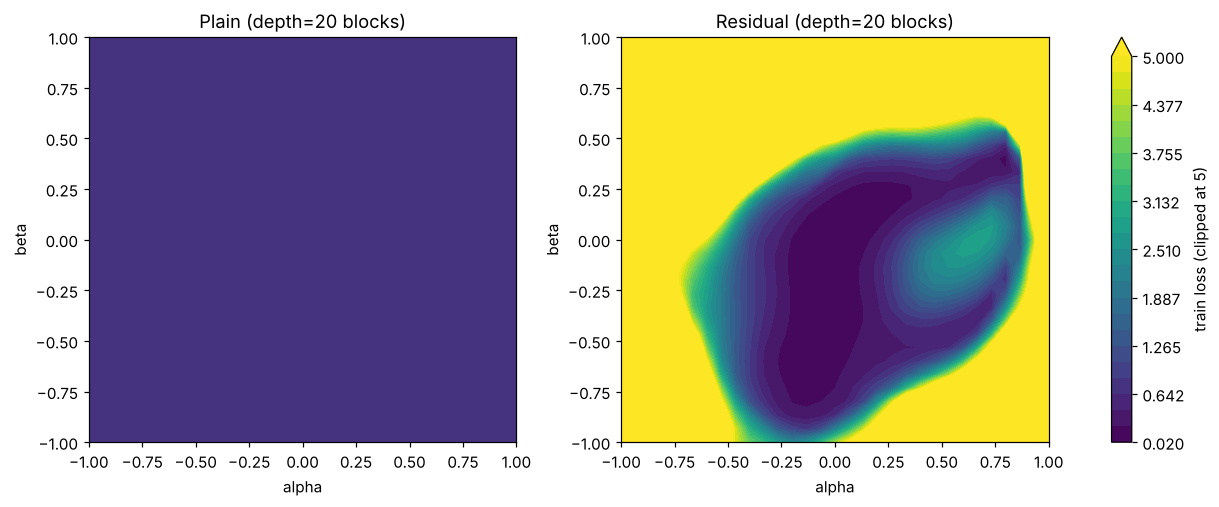

In [12]:
DEPTH = 20
STEPS = 1500
nets = {}
for skip in (False, True):
    net, h = train(DEPTH, skip, steps=STEPS)
    nets[skip] = net
    print(f"skip={skip!s:5}  depth={DEPTH}  final train loss = {h[-1]:.4f}")

t0 = time.time()
surfaces = {skip: loss_surface(nets[skip]) for skip in nets}
print(f"surfaces computed in {time.time()-t0:.0f}s")

# Same contour levels for both panels, otherwise the comparison is meaningless
allZ = np.concatenate([Z.ravel() for _, Z in surfaces.values()])
levels = np.linspace(allZ.min(), min(allZ.max(), 5.0), 25)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, skip in zip(axes, (False, True)):
    a, Z = surfaces[skip]
    cs = ax.contourf(a, a, Z.T, levels=levels, extend="max")
    ax.set_title(f"{'Residual' if skip else 'Plain'} (depth={DEPTH} blocks)")
    ax.set_xlabel("alpha"); ax.set_ylabel("beta"); ax.grid(False)
fig.colorbar(cs, ax=axes, label="train loss (clipped at 5)")
plt.show()

### 4b. 3D surfaces and 1D slices

A 3D view makes "smooth bowl vs jagged terrain" more tangible. The 1D slices (many random directions, one curve each) are cheaper and often easier to read than a contour plot.

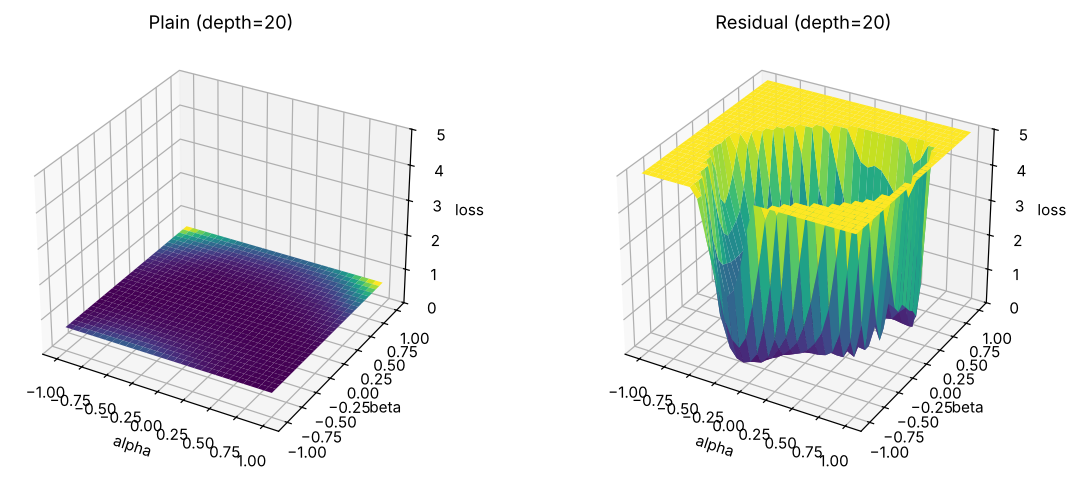

In [13]:
fig = plt.figure(figsize=(11, 4.5))
zmax = min(allZ.max(), 5.0)
for k, skip in enumerate((False, True)):
    a, Z = surfaces[skip]
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    A, B = np.meshgrid(a, a, indexing="ij")
    ax.plot_surface(A, B, np.minimum(Z, zmax), cmap="viridis", linewidth=0, antialiased=True)
    ax.set_zlim(0, zmax)
    ax.set_title(f"{'Residual' if skip else 'Plain'} (depth={DEPTH})")
    ax.set_xlabel("alpha"); ax.set_ylabel("beta"); ax.set_zlabel("loss")
plt.tight_layout(); plt.show()

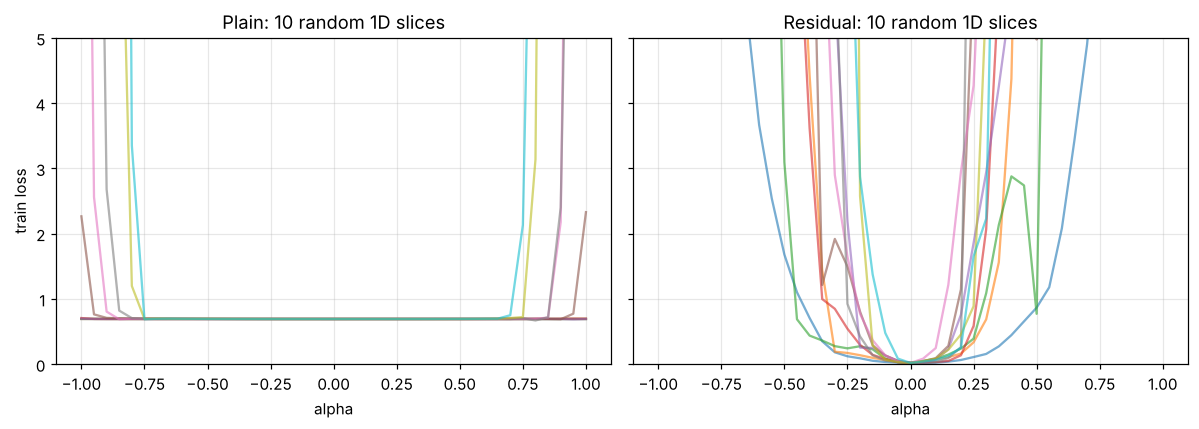

In [14]:
@torch.no_grad()
def slices_1d(net, n_dirs=10, span=1.0, n=41, seed=100):
    base = [p.clone() for p in net.parameters()]
    xs = np.linspace(-span, span, n)
    curves = []
    for k in range(n_dirs):
        g = torch.Generator().manual_seed(seed + k)
        d = random_direction(net, g)
        curves.append([loss_at(net, base, (d,), (a,)) for a in xs])
    for p, p0 in zip(net.parameters(), base):
        p.copy_(p0)
    return xs, np.array(curves)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, skip in zip(axes, (False, True)):
    xs, C = slices_1d(nets[skip])
    ax.plot(xs, C.T, alpha=0.6)
    ax.set_title(f"{'Residual' if skip else 'Plain'}: 10 random 1D slices")
    ax.set_xlabel("alpha"); ax.set_ylim(0, 5)
axes[0].set_ylabel("train loss")
plt.tight_layout(); plt.show()

### 4c. Depth sweep of the landscape

Does the difference grow with depth, as Li et al. report? Same code at depths 2, 10 and 20 (coarser grid to keep it fast). Final training losses are printed above each panel so you can tell a "trained and smooth" net from a "stuck on a plateau" net.

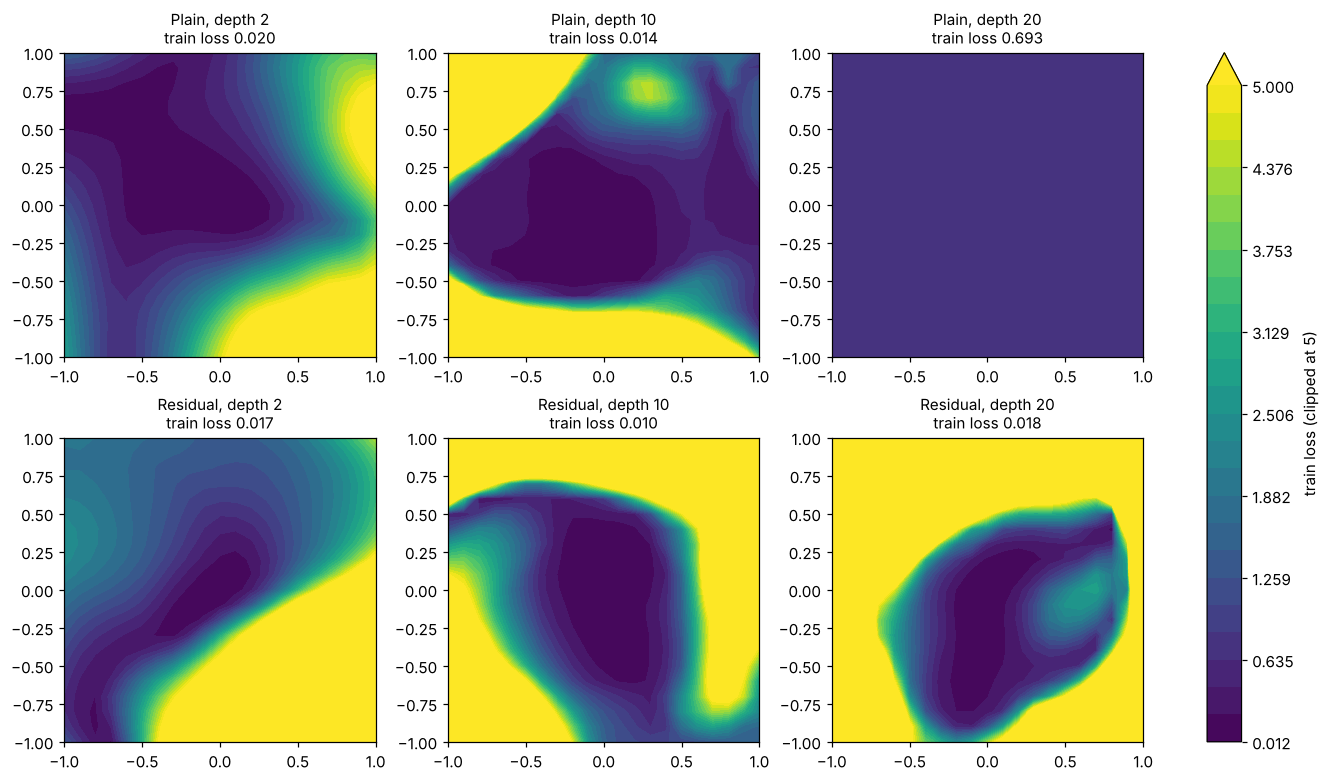

In [15]:
sweep_depths = [2, 10, 20]
fig, axes = plt.subplots(2, len(sweep_depths), figsize=(12, 7), constrained_layout=True)
sweep_surf = {}
for r, skip in enumerate((False, True)):
    for c, dpt in enumerate(sweep_depths):
        net, h = train(dpt, skip, steps=STEPS)
        sweep_surf[(skip, dpt)] = (loss_surface(net, n=21), h[-1])
allZ2 = np.concatenate([s[0][1].ravel() for s in sweep_surf.values()])
levels2 = np.linspace(allZ2.min(), min(allZ2.max(), 5.0), 25)
for (skip, dpt), ((a, Z), final) in sweep_surf.items():
    ax = axes[0 if not skip else 1, sweep_depths.index(dpt)]
    cs = ax.contourf(a, a, Z.T, levels=levels2, extend="max")
    ax.set_title(f"{'Residual' if skip else 'Plain'}, depth {dpt}\ntrain loss {final:.3f}", fontsize=10)
    ax.grid(False)
fig.colorbar(cs, ax=axes, label="train loss (clipped at 5)")
plt.show()

**What this run shows (your exact picture will vary with seed and steps):**

- Depth 2 and 10: both nets sit in a clear basin. The residual basin is not obviously smoother or wider. The shapes differ, but neither is "chaotic".
- Depth 20: the plain net never trains, so its panel is a flat plateau. The residual net finds a basin, with a steep wall around it (the blow-up outside it comes from activations compounding across blocks, since this net has no normalization).

The honest teaching point: on a small problem the **trainability** benefit of skips (Experiment 2) is large and reproducible, while the **smoother landscape** effect is subtle and needs deep BN CNNs to show up clearly. Do not oversell the contour plots.

## Experiment 5: a reality check with numbers

Contour plots invite both over-reading and "that's cherry-picked". Two slice-independent measures of sharpness around the solution:

1. **Average loss increase along random filter-normalized directions** at several radii.
2. **Top Hessian eigenvalue** by power iteration (Hessian-vector products via double backprop).

We run both with and without LayerNorm. Compare only nets that reached a similar training loss: a dead net (loss 0.693) has near-zero sharpness trivially, which is not a virtue.

In [16]:
@torch.no_grad()
def mean_loss_increase(net, radii=(0.1, 0.25, 0.5, 1.0), n_dirs=40, seed=1000):
    base = [p.clone() for p in net.parameters()]
    base_loss = loss_at(net, base, ([torch.zeros_like(p) for p in base],), (0.0,))
    out = {r: [] for r in radii}
    for k in range(n_dirs):
        g = torch.Generator().manual_seed(seed + k)
        d = random_direction(net, g)
        for r in radii:
            out[r].append(loss_at(net, base, (d,), (r,)) - base_loss)
    for p, p0 in zip(net.parameters(), base):
        p.copy_(p0)
    return base_loss, {r: (np.mean(v), np.std(v)) for r, v in out.items()}

def top_hessian_eig(net, iters=40, seed=0):
    params = [p for p in net.parameters()]
    loss = F.binary_cross_entropy_with_logits(net(X), y)
    grads = torch.autograd.grad(loss, params, create_graph=True)
    g = torch.Generator().manual_seed(seed)
    v = [torch.randn(p.shape, generator=g) for p in params]
    nv = math.sqrt(sum((t ** 2).sum().item() for t in v)); v = [t / nv for t in v]
    eig = 0.0
    for _ in range(iters):
        Hv = torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)
        eig = sum((h * t).sum() for h, t in zip(Hv, v)).item()
        nh = math.sqrt(sum((h ** 2).sum().item() for h in Hv)) + 1e-12
        v = [h / nh for h in Hv]
    return eig

(130s)
 norm arm       depth  train loss  mean dL @ r=0.25  top Hessian eig
False plain         5      0.0160            1.0831           381.30
False plain        10      0.0142            0.5828           230.06
False plain        20      0.6931            0.0000             0.31   <- did not train
False residual      5      0.0087            0.7952           358.80
False residual     10      0.0105            0.2141           226.06
False residual     20      0.0184            0.2073           177.36
 True plain         5      0.0076            0.4648           621.49
 True plain        10      0.0139            0.3058           159.11
 True plain        20      0.1810            0.5838             1.21
 True residual      5      0.0069            0.4821           395.20
 True residual     10      0.0065            0.3373           114.68
 True residual     20      0.0046            1.1764           237.58


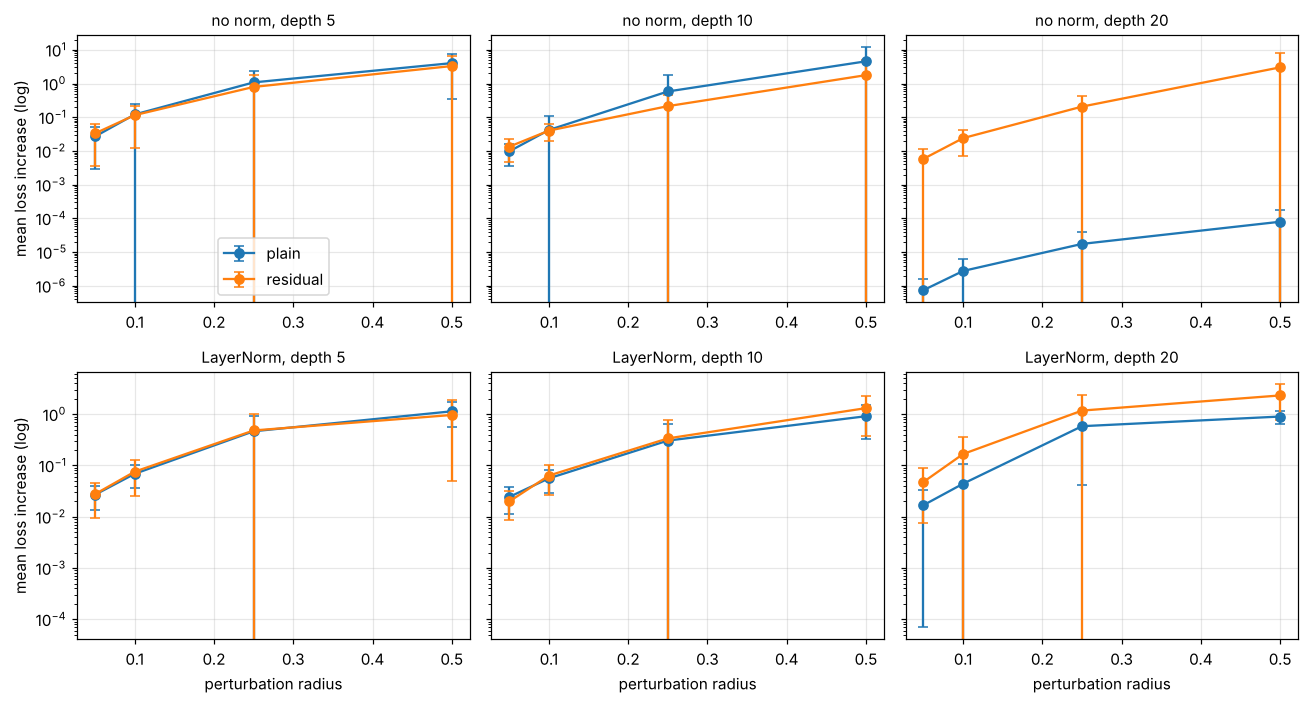

In [17]:
sharp_depths = [5, 10, 20]
radii = (0.05, 0.1, 0.25, 0.5)
rows, curves = [], {}
t0 = time.time()
for norm in (False, True):
    for skip in (False, True):
        for dpt in sharp_depths:
            net, h = train(dpt, skip, steps=STEPS, norm=norm)
            base_loss, inc = mean_loss_increase(net, radii=radii, n_dirs=30)
            rows.append((norm, skip, dpt, h[-1], inc[0.25][0], top_hessian_eig(net)))
            curves[(norm, skip, dpt)] = inc
print(f"({time.time()-t0:.0f}s)")

print(f"{'norm':>5s} {'arm':9s} {'depth':>5s} {'train loss':>11s} {'mean dL @ r=0.25':>17s} {'top Hessian eig':>16s}")
for norm, skip, dpt, tl, dl, eig in rows:
    flag = "   <- did not train" if tl > 0.6 else ""
    print(f"{str(norm):>5s} {'residual' if skip else 'plain':9s} {dpt:5d} {tl:11.4f} {dl:17.4f} {eig:16.2f}{flag}")

fig, axes = plt.subplots(2, len(sharp_depths), figsize=(12, 6.5), sharey="row")
for r, norm in enumerate((False, True)):
    for c, dpt in enumerate(sharp_depths):
        ax = axes[r, c]
        for skip in (False, True):
            inc = curves[(norm, skip, dpt)]
            rs = sorted(inc)
            m = np.array([inc[x][0] for x in rs]); sd = np.array([inc[x][1] for x in rs])
            ax.errorbar(rs, m, yerr=sd, marker="o", capsize=3, label="residual" if skip else "plain")
        ax.set_yscale("log")
        ax.set_title(f"{'LayerNorm' if norm else 'no norm'}, depth {dpt}", fontsize=10)
        if r == 1: ax.set_xlabel("perturbation radius")
    axes[r, 0].set_ylabel("mean loss increase (log)")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

**How to read this.** If the "residual landscape is smoother" story held strongly on this toy problem, the residual curves would sit consistently below the plain ones for the nets that trained. In our run they do not: at shallow depth the two are comparable and the ordering flips between settings, and at depth 20 the plain net either fails to train (so its tiny sharpness is meaningless) or trains worse. The number agrees with Experiment 2 (skips make deep nets *trainable*) but does not confirm a clean smoothness advantage at this scale.

That is consistent with the literature: the smoothness effect is clearest for deep BatchNorm CNNs (ResNet-56+), and sharpness metrics are sensitive to parameter scale and to how low the loss is. If you want to show the paper's figure faithfully, run the same `loss_surface` code on a deep CNN with and without skips on CIFAR-10.

## Summary: what each experiment shows

| Experiment | Evidence | What it supports | Strength |
|---|---|---|---|
| 1 / 1b | Gradient and activation scale per block at init | Skips give gradients and signals a direct path (`dy/dx = dF/dx + 1`) | Strong, mechanistic |
| 2 / 2b | Training loss vs depth | Deep plain nets fail to optimize; residual nets keep improving (train loss, so not overfitting) | Strong, reproducible |
| 2c | Same sweep with LayerNorm | Skips and normalization help in different ways; norm alone does not rescue depth 40 | Strong |
| 3 | Zero-init branch = identity | The default behavior of a residual block is "do nothing", so extra depth is cheap | Illustrative |
| 4 | Contours, 3D, 1D slices | Trained basin vs dead plateau at depth 20; no clean smoothness win at this scale | Weak, qualitative |
| 5 | Loss increase and Hessian eigenvalue | Mixed results here; smoothness claim needs deep BN CNNs to show clearly | Reality check |

**Discussion questions for students**

1. Why can a plain network sit at loss 0.693 and have a perfectly flat "landscape"? What does that say about reading sharpness numbers without checking the loss?
2. Your original block applies ReLU *after* the addition. How does the pre-activation variant (`x + F(norm(x))`) change the identity path, and why do Transformers use it?
3. Why does the residual net without normalization have steep walls around its basin? What would a learnable gate initialized at 0 (ReZero / Highway style) change?
4. What would you need to change (model, data, depth) to reproduce the smooth-vs-chaotic figure from Li et al.?